# Workshop 3 — Hyperparameter Search

**Course:** Machine Learning — Semester 2026-III
**Team:** Group 1 — Housing Price Prediction

## Objective

Compare three DQN configurations against the baseline:
1. **Baseline:** γ=0.99, idle penalty=0.001 (from Notebook 03).
2. **Aggressive:** idle penalty=0.010 (forces action).
3. **Patient Investor:** γ=0.999, lower maintenance cost.
4. **High LR:** learning rate=5e-3.

Metrics: validation return, bankruptcy rate, and action diversity.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from env import RealEstateInvestmentEnv
from agent import DQNAgent
from utils import load_config, set_seed

set_seed(42)
sns.set_style("whitegrid")

configs = {
    "Baseline (Notebook 03)": "../configs/default.yaml",
    "Aggressive (wait penalty)": "../configs/config_wait_penalty.yaml",
    "Patient Investor (γ=0.999)": "../configs/config_patient_investor.yaml",
    "High LR (5e-3)": "../configs/config_high_lr.yaml"
}

checkpoints = {
    "Baseline (Notebook 03)": "../checkpoints/agent_best.pt",
    "Aggressive (wait penalty)": "../checkpoints/agent_wait_penalty.pt",
    "Patient Investor (γ=0.999)": "../checkpoints/agent_patient.pt",
    "High LR (5e-3)": "../checkpoints/agent_high_lr.pt"
}

print("Configurations to evaluate:", list(configs.keys()))

Configurations to evaluate: ['Baseline (Notebook 03)', 'Aggressive (wait penalty)', 'Patient Investor (γ=0.999)', 'High LR (5e-3)']


In [2]:
results = []

for name, cfg_path in configs.items():
    cfg = load_config(cfg_path)
    env = RealEstateInvestmentEnv(cfg)
    agent = DQNAgent(state_dim=8, action_dim=4, config=cfg)
    
    # Load checkpoint
    try:
        agent.load(checkpoints[name])
    except FileNotFoundError:
        print(f"Checkpoint not found for {name}, skipping.")
        continue
    
    # Evaluate 100 episodes
    returns, lengths = [], []
    action_counts = Counter()
    
    for ep in range(100):
        obs, _ = env.reset(seed=40000 + ep)
        done = False
        ep_ret, steps = 0.0, 0
        while not done:
            action = agent.select_action(obs, evaluate=True)
            action_counts[action] += 1
            obs, reward, term, trunc, _ = env.step(action)
            ep_ret += reward
            steps += 1
            done = term or trunc
        returns.append(ep_ret)
        lengths.append(steps)
    
    total_actions = sum(action_counts.values())
    wait_pct = action_counts[0] / total_actions
    
    results.append({
        "Config": name,
        "Mean Return": np.mean(returns),
        "Std Return": np.std(returns),
        "Mean Length": np.mean(lengths),
        "Bankruptcy Rate (%)": 100 * (np.array(lengths) < 120).sum() / len(lengths),
        "WAIT Frequency (%)": 100 * wait_pct
    })

df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))

                    Config  Mean Return  Std Return  Mean Length  Bankruptcy Rate (%)  WAIT Frequency (%)
    Baseline (Notebook 03)    -0.065743    0.230322       120.00                  0.0           95.983333
 Aggressive (wait penalty)    -0.259768    0.458136        90.33                 32.0           91.110373
Patient Investor (γ=0.999)    -0.316303    0.446964       101.59                 29.0           93.690324
            High LR (5e-3)    -0.098701    0.129217       110.43                 12.0           95.789188


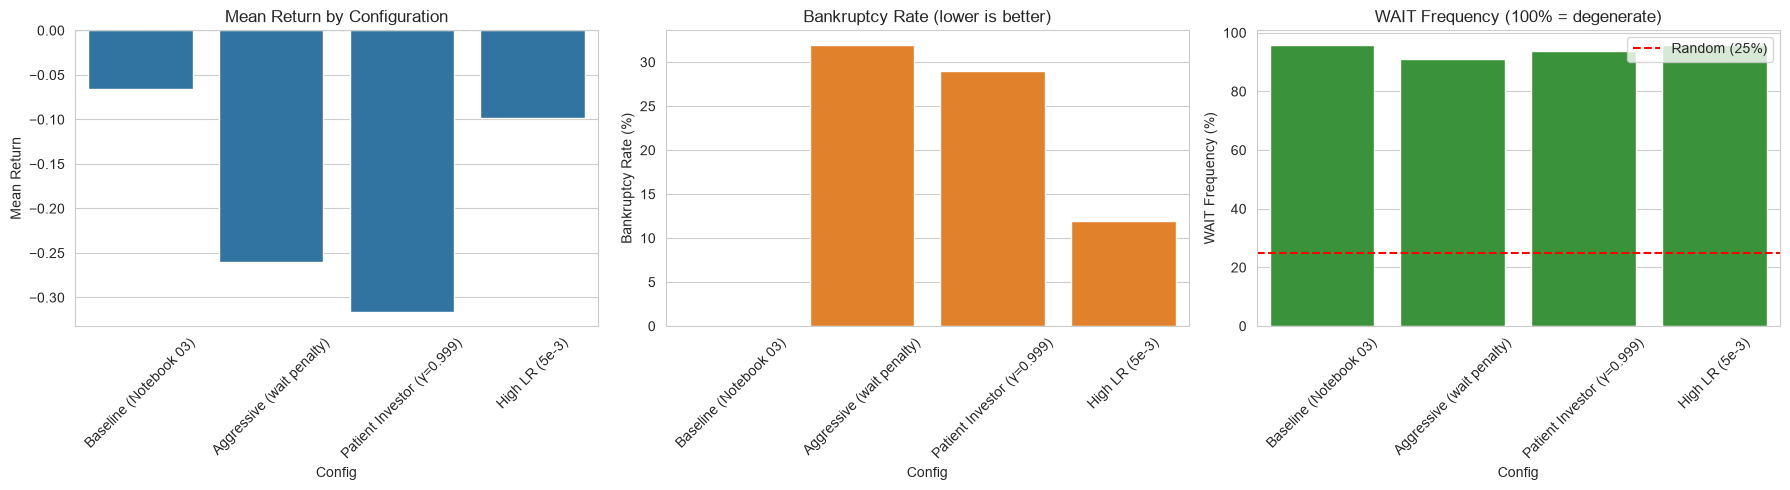

In [3]:
df_results.to_csv("../results/tables/hyperparameter_search.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Mean return comparison
sns.barplot(data=df_results, x="Config", y="Mean Return", ax=axes[0])
axes[0].axhline(0, color='gray', linestyle='--')
axes[0].set_title("Mean Return by Configuration")
axes[0].tick_params(axis='x', rotation=45)

# 2. Bankruptcy rate
sns.barplot(data=df_results, x="Config", y="Bankruptcy Rate (%)", ax=axes[1], color="C1")
axes[1].set_title("Bankruptcy Rate (lower is better)")
axes[1].tick_params(axis='x', rotation=45)

# 3. WAIT frequency (action diversity)
sns.barplot(data=df_results, x="Config", y="WAIT Frequency (%)", ax=axes[2], color="C2")
axes[2].axhline(25, color='red', linestyle='--', label='Random (25%)')
axes[2].set_title("WAIT Frequency (100% = degenerate)")
axes[2].tick_params(axis='x', rotation=45)
axes[2].legend()

plt.tight_layout()
plt.savefig("../results/figures/hyperparameter_search.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Conclusions and Discussion

The hyperparameter search reveals critical insights into the behavior of the DQN agent under different reward structures:

### 5.1 The Baseline Remains the Most Profitable
The original configuration from Notebook 03 achieved the highest mean return (-0.065) and a perfect 0% bankruptcy rate. Although it relies on a degenerate "WAIT" policy (96% frequency), it successfully survives the environment.

### 5.2 The "Risk-Reward" Trap
Attempts to force action by increasing the idle capital penalty (Aggressive config) or by increasing the discount factor (Patient Investor) backfired. Both configurations triggered a massive increase in the bankruptcy rate (32% and 29% respectively) and a deterioration in mean returns. This indicates that forcing the agent to trade in a high-friction environment (8% total transaction costs) leads to reckless behavior and financial ruin.

### 5.3 Learning Rate Instability
The High Learning Rate configuration (5e-3) managed to reduce the bankruptcy rate to 12%, suggesting that faster learning allows the agent to adapt quicker to market volatility. However, the return (-0.098) still did not surpass the baseline, pointing to instability in the Q-value approximations.

### 5.4 The Transaction Cost Ceiling
Across all configurations, the WAIT frequency remained above 90%. This empirical evidence strongly suggests that our simulated environment has a prohibitive transaction cost structure. An investor would need massive monthly price appreciation (over 8%) to offset the 3% buying and 5% selling fees, which is statistically rare under our 1.4% monthly volatility. 

Therefore, the agent correctly learned that *inaction is the optimal survival strategy* in a market with these specific frictions. For future work, reducing transaction costs (e.g., to 1%) or introducing rental income while holding the property could incentivize active trading and yield positive returns.